# ParseTune — end-to-end walkthrough

Schema-instructable receipt extraction: Phi-3.5-mini (3.8B) fine-tuned with QLoRA on Apple's MLX,
on a MacBook Pro (M5 Pro, 24 GB). Hand it receipt text and **any** schema `{field: description}`;
it returns exactly those keys, values copied from the receipt, `null` for anything not there.

This notebook walks the six phases. It inspects the data, plots both training runs, runs **one
live extraction** (including field names the model never trained on), and loads the saved Phase 4
and Phase 5 results. The heavy steps — building the data, training, the full benchmarks — are
shown as commands rather than re-run: each takes minutes to hours, and their outputs are saved in
the repository.

**Needs:** an Apple Silicon Mac; the `.venv` from the README's Setup plus
`notebooks/requirements.txt`. The live cell also needs the converted base model (`models/`) and the
v2 adapter (`train/adapters/phi35-sroie-v2/`), both produced by `train/sft_train.py`. Don't run the
live cell while a training run or benchmark is using the GPU.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

# Quiet two harmless import-time notices (no PyTorch needed: MLX does the work;
# tqdm's widget warning) - set before anything imports transformers.
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path[:0] = [str(ROOT / "evaluate"), str(ROOT / "data")]
RESULTS = ROOT / "evaluate" / "results"

import pandas as pd
pd.set_option("display.max_colwidth", 90)
print("project:", ROOT.name)

project: parseTUNE


## Phase 1 — Data

SROIE receipts → instruction pairs. The schema in each prompt carries descriptions (the bridge to
unseen field names); answers are verbatim OCR spans; the 7 receipts SROIE repeats across train and
test are dropped from train; and each training receipt gets one extra example mixing real fields
with fields it does not carry — real `null` answers, no generated text.

In [2]:
info = json.loads((ROOT / "data/processed/dataset_info.json").read_text())
print("examples per split:", info["counts"])
s = info["stats"]
print(f"train receipts {s['train_receipts']}, cross-split duplicates dropped {s['dropped_split_overlap']}, "
      f"absent-field examples {s['absent_variant_examples']}, null answers {s['null_slots']}")
print("\nthe four SROIE fields:")
for f, d in info["fields"].items():
    print(f"  {f:8s} {d}")

examples per split: {'train': 1671, 'validation': 62, 'test': 347}
train receipts 557, cross-split duplicates dropped 7, absent-field examples 557, null answers 495

the four SROIE fields:
  company  name of the merchant or business issuing the receipt
  date     date of purchase, exactly as printed on the receipt
  address  full street address of the merchant
  total    final total amount paid


In [3]:
train = json.loads((ROOT / "data/processed/train.json").read_text())
four_field = train[0]
mixed = next(r for r in train if "schema_spec" in r and None in r["target"].values())
for title, row in (("four-field example", four_field), ("absent-field example", mixed)):
    print(f"--- {title} ({row['id']}) ---")
    print("schema :", json.dumps(row.get("schema_spec") or row["schema"]))
    print("answer :", row["completion"][0]["content"], "\n")
print("receipt text of the first example (12 lines):")
print("\n".join(four_field["receipt_text"].splitlines()[:12]))

--- four-field example (sroie-train-00000-v0) ---
schema : ["company", "date", "address", "total"]
answer : {"company": "SANYU STATIONERY SHOP", "date": "06/07/2017", "address": "NO. 31G&33G, JALAN SETIA INDAH X ,U13/X 40170 SETIA ALAM", "total": "4.5000"} 

--- absent-field example (sroie-train-01114-v2) ---
schema : {"total": "final total amount paid", "date": "date of purchase, exactly as printed on the receipt", "time_of_purchase": "time of purchase, exactly as printed on the receipt"}
answer : {"total": "4.5000", "date": "06/07/2017", "time_of_purchase": null} 

receipt text of the first example (12 lines):
SANYU STATIONERY SHOP
NO. 31G&33G, JALAN SETIA INDAH X ,U13/X
40170 SETIA ALAM
Mobile /Whatsapps : +6012-918 7937
Tel: +603-3362 4137
GST ID No: 001531760640 TAX INVOICE
Owned By :
SANYU SUPPLY SDN BHD (1135772-K)
CASH SALES COUNTER
1. 2000-0063 S-69 MULTI PURPOSE PAPER
40'S A4 120GSM
1 × 4.5000 4.50 SR


## Phase 2 — Training

```bash
caffeinate -i python train/sft_train.py    # converts the base once, proves the loss mask, trains (~2 h 15 min)
```

LoRA rank 16 on all four fused projections in all 32 blocks (25.17M trainable parameters), batch
2 × 4, lr 2e-4 cosine, 3 epochs. v1 trained on the four-field data; v2 adds the absent-field
examples and was adopted on validation (it answers `null` for absent fields without losing
accuracy).

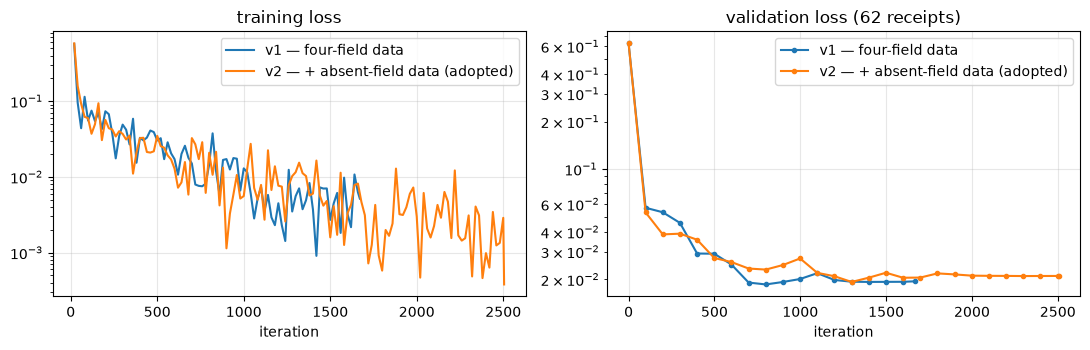

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for label, rel in (("v1 — four-field data", "train/adapters/phi35-sroie"),
                   ("v2 — + absent-field data (adopted)", "train/adapters/phi35-sroie-v2")):
    path = ROOT / rel / "run_log.json"
    if not path.exists():
        print("not found (adapters are not in git):", path)
        continue
    log = json.loads(path.read_text())
    axes[0].plot([r["iteration"] for r in log["train"]], [r["train_loss"] for r in log["train"]], label=label)
    axes[1].plot([r["iteration"] for r in log["val"]], [r["val_loss"] for r in log["val"]], marker="o", ms=3, label=label)
axes[0].set(title="training loss", xlabel="iteration", yscale="log")
axes[1].set(title="validation loss (62 receipts)", xlabel="iteration", yscale="log")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## Phase 3 — One live extraction, any schema

The same receipt, asked two ways: SROIE's four fields, and a schema with renamed keys in a new
order plus `loyalty_card_number` — a field this receipt does not carry (no loyalty, member or card
text anywhere on it), so the right answer is `null`.

In [5]:
from predict import load_model, load_template, predict

template = load_template()
model, tokenizer = load_model(adapter_path=ROOT / "train/adapters/phi35-sroie-v2")
receipt = json.loads((ROOT / "data/processed/validation.json").read_text())[1]
schemas = {
    "the four SROIE fields": dict(template.fields),
    "renamed, reordered, plus an absent field": {
        "amount_due": "final total amount paid",
        "merchant_name": "name of the merchant or business issuing the receipt",
        "loyalty_card_number": "membership or loyalty card number of the customer",
    },
}
records, _ = predict(model, tokenizer, template,
                     [(receipt["receipt_text"], schema) for schema in schemas.values()], batch_size=2)
for title, record in zip(schemas, records):
    print(f"{title}:\n  {record['raw']}\n")
print("gold (four fields):", receipt["target"])

the four SROIE fields:
  {"company": "TF Value-Mart Sdn Bhd", "date": "19/05/18", "address": "Jalan Tras Batu 1 28700 Bentong Pahang Darul Makmur.", "total": "52.80"}

renamed, reordered, plus an absent field:
  {"amount_due": "52.80", "merchant_name": "TF Value-Mart Sdn Bhd", "loyalty_card_number": null}

gold (four fields): {'company': 'TF Value-Mart Sdn Bhd', 'date': '19/05/18', 'address': 'Jalan Tras Batu 1 28700 Bentong Pahang Darul Makmur.', 'total': '52.80'}


## Phase 4 — Benchmark (test split, 347 receipts)

```bash
caffeinate -i python -u evaluate/benchmark.py > evaluate/results/benchmark.log 2>&1
```

Loaded from the saved runs. *Normalised* compares totals as amounts, dates as calendar dates, text
case-insensitively; F1 is on non-null values; intervals are 95% bootstrap over receipts.

In [6]:
from report import SYSTEM_ORDER, phase4_runs

runs = phase4_runs(batch_size=2)
rows = []
for name in SYSTEM_ORDER:
    if name not in runs:
        continue
    m = runs[name]["metrics"]
    mi, ci = m["micro"], m["ci95"]["normalised"]
    rows.append({"system": name, "exact": mi["exact"], "normalised": mi["normalised"],
                 "95% CI (normalised)": f"{100 * ci[0]:.1f}–{100 * ci[1]:.1f}",
                 "precision": mi["precision"], "recall": mi["recall"], "F1": mi["f1"],
                 "valid JSON": m["json_valid_raw"], "schema adherence": m["schema_adherence"]})
table = pd.DataFrame(rows).set_index("system")
table.style.format({c: "{:.1%}" for c in table.columns if c != "95% CI (normalised)"})

,exact,normalised,95% CI (normalised),precision,recall,F1,valid JSON,schema adherence
system,,,,,,,,
parsetune,93.7%,94.2%,92.9–95.5,94.5%,94.2%,94.4%,99.7%,99.7%
zero-shot-bf16,55.0%,68.0%,66.0–70.2,68.0%,68.0%,68.0%,100.0%,100.0%
three-shot,41.4%,54.3%,51.5–56.8,56.3%,54.3%,55.2%,96.5%,96.0%
zero-shot,33.6%,44.6%,41.7–47.6,50.6%,44.6%,47.4%,88.2%,87.6%


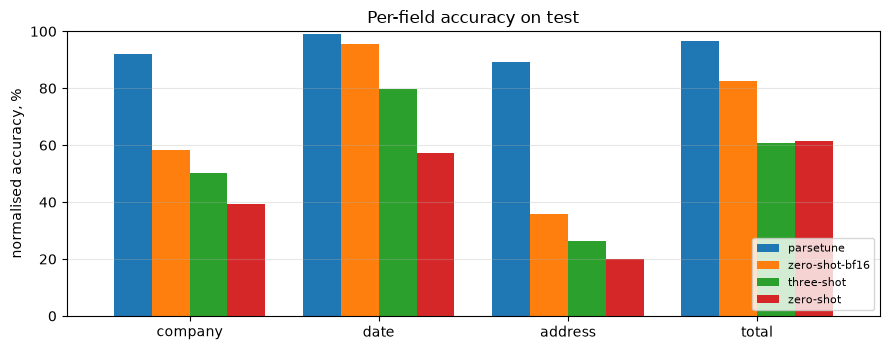

In [7]:
fields = ["company", "date", "address", "total"]
per_field = pd.DataFrame({name: [runs[name]["metrics"]["fields"][f]["normalised"] for f in fields]
                          for name in SYSTEM_ORDER if name in runs}, index=fields)
ax = (100 * per_field).plot.bar(figsize=(9, 3.6), rot=0, width=0.8)
ax.set(ylabel="normalised accuracy, %", ylim=(0, 100), title="Per-field accuracy on test")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## Phase 5 — Schema-instructability (test split, held-out conditions)

```bash
caffeinate -i python -u evaluate/schema_probe.py --conditions phase5 --name parsetune-v2 \
    --adapter train/adapters/phi35-sroie-v2
```

None of these field names appeared in training: renamed fields, a random subset in random order,
novel fields never supervised, and a field no receipt carries (`shipping_tracking_number`).

In [8]:
from report import phase5_runs

p5 = phase5_runs()
rows = []
for name in ("parsetune-v2", "parsetune-v1", "zero-shot-bf16", "zero-shot-4bit"):
    if name not in p5:
        continue
    slots = p5[name]["scores"]["slots"]
    row = {"system": name}
    for cond in ("renamed", "subset_order", "absent (four fields)"):
        s = slots[cond]
        row[f"{cond}: printed right"] = s["normalised_right"] / s["present"]
    a = slots["absent (absent slot)"]
    row["absent field → null"] = a["absent_null"] / a["absent"]
    for field, c in p5[name]["scores"]["novel"].items():
        if c["labelled"]:
            row[f"novel {field}: agrees with silver"] = c["agree"] / c["labelled"]
    rows.append(row)
p5_table = pd.DataFrame(rows).set_index("system").T
p5_table.style.format("{:.1%}")

system,parsetune-v2,parsetune-v1,zero-shot-bf16,zero-shot-4bit
renamed: printed right,96.1%,96.1%,77.8%,53.3%
subset_order: printed right,94.1%,94.3%,65.9%,46.6%
absent (four fields): printed right,94.3%,94.5%,67.5%,45.4%
absent field → null,100.0%,0.0%,96.5%,92.8%
novel payment_method: agrees with silver,74.3%,82.1%,99.0%,98.6%
novel gst_id: agrees with silver,89.8%,75.0%,99.0%,98.7%


## Everything else

- `evaluate/results/REPORT.md` — every number above and more (per-field precision / recall / F1,
  batch-size sensitivity, the manual spot-check), regenerated by `python evaluate/report.py`.
- `decisions.md` — every decision, and what changed the ones that changed.
- `memory.md` — phases, architecture, scope, artifacts, open items.
- `MODEL_CARD.md` — the adapter card and how to publish it.